In [71]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


 # **3. Exploratory Data Analysis** (EDA):

## 3.1. & 3.2

In [72]:
df = pd.read_csv("group_23_train.csv")

print(f"The shape of the table: {df.shape}" ,"\n"  ,"_________________________________ \n" )
print("The info of the table: \n " )

df.info()

print("_________________________________")
print("\n The statistic describtion of the target: \n " ) # we can describe what we need

df["y"].describe()

The shape of the table: (100000, 35) 
 _________________________________ 

The info of the table: 
 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 35 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   f1      100000 non-null  object 
 1   f2      100000 non-null  object 
 2   f3      100000 non-null  float64
 3   f4      56139 non-null   float64
 4   f5      100000 non-null  float64
 5   f6      100000 non-null  object 
 6   f7      99848 non-null   object 
 7   f8      100000 non-null  object 
 8   f9      100000 non-null  object 
 9   f10     99983 non-null   object 
 10  f11     100000 non-null  object 
 11  f12     99694 non-null   object 
 12  f13     98440 non-null   object 
 13  f14     97885 non-null   float64
 14  f15     74063 non-null   float64
 15  f16     97767 non-null   float64
 16  f17     98177 non-null   float64
 17  f18     97721 non-null   float64
 18  f19     97715 non-null  

count    100000.000000
mean          2.213720
std           0.487387
min           1.000000
25%           2.000000
50%           2.000000
75%           2.000000
max           4.000000
Name: y, dtype: float64

In [73]:
print("_________________________________")
print("\n The first 5 rows of the table: \n " )

df.head()

_________________________________

 The first 5 rows of the table: 
 


,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,...,f26,f27,f28,f29,f30,f31,f32,f33,f34,y
0,Source1,5/29/2021 14:56,34.028059,-118.196987,0.610,Accident on Whittier Blvd (CA-60) from Lorena ...,CA-60 E,Los Angeles,CA,90023,...,False,False,False,False,False,False,False,Day,Day,2
1,Source1,10:43.0,33.894340,-80.183103,0.183,Incident on MYRTLE BEACH HWY near DAFFODIL LN ...,Myrtle Beach Hwy,Sumter,SC,29153-8896,...,False,False,False,False,False,False,False,Night,Day,2
2,Source1,2/9/2022 16:58,41.736997,-72.757589,1.089,ConnDOT: Crash (2 Vehicle) on I-84 Westbound b...,I-84 W,Hartford,CT,6110,...,False,False,False,False,False,False,False,Day,Day,2
3,Source2,10/5/2018 16:43,42.339859,NaN,0.000,Accident on Summer St near Power House St.,Summer St,Suffolk,MA,02127-1610,...,False,False,False,False,False,False,False,Day,Day,2
4,Source2,2/27/2018 16:57,28.468746,NaN,0.000,Right lane blocked due to multi-vehicle accide...,I-4 E,Orange,FL,32819,...,False,False,False,False,False,False,False,Day,Day,3


In [74]:
# Numerical feature summary
df.describe()

,f3,f4,f5,f14,f15,f16,f17,f18,f20,y
count,100000.000000,56139.000000,100000.000000,97885.000000,74063.000000,97767.000000,98177.000000,97721.000000,71516.000000,100000.000000
mean,36.206659,-95.746360,0.567197,61.569867,58.154370,64.859329,29.535760,9.081572,0.008336,2.213720
std,5.078032,18.099216,1.762371,18.993451,22.354601,22.795040,1.012963,2.634465,0.103095,0.487387
min,24.646915,-124.485680,0.000000,-27.900000,-53.200000,1.000000,19.640000,0.000000,0.000000,1.000000
25%,33.392145,-117.720860,0.000000,49.000000,42.500000,48.000000,29.360000,10.000000,0.000000,2.000000
50%,35.832679,-88.037930,0.031000,64.000000,62.000000,67.000000,29.860000,10.000000,0.000000,2.000000
75%,40.095038,-80.250395,0.466000,76.000000,75.000000,84.000000,30.030000,10.000000,0.000000,2.000000
max,48.949268,-67.109242,118.852000,196.000000,196.000000,100.000000,30.950000,80.000000,10.010000,4.000000


## 3.3 Feature Relationship

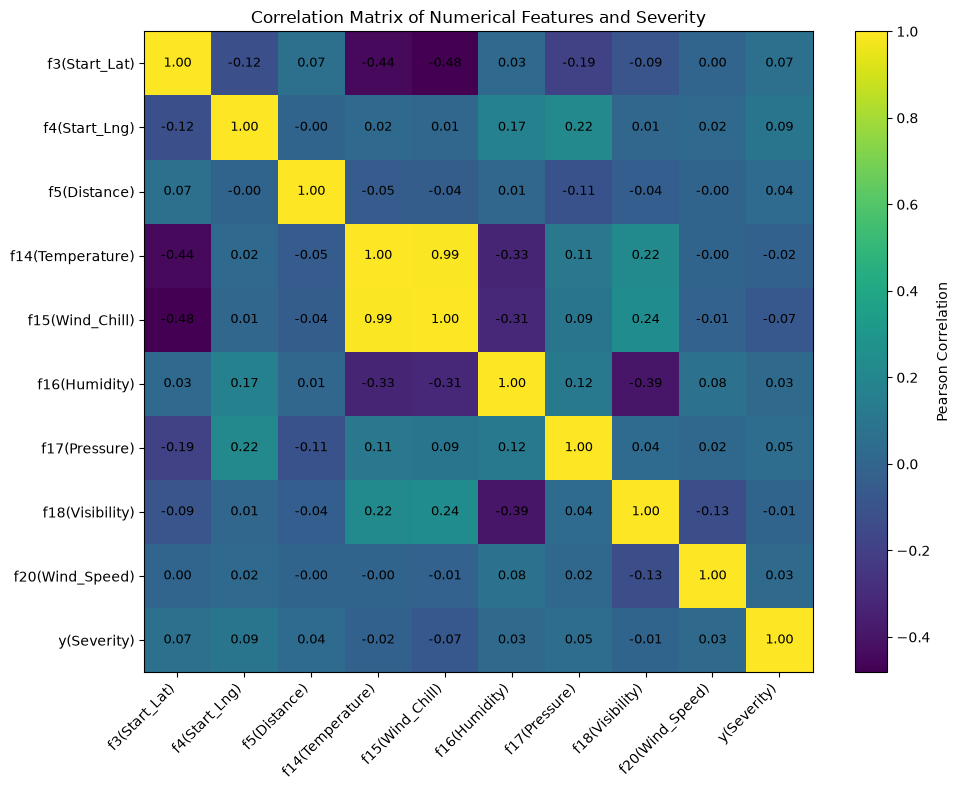

In [75]:
# Numerical features based on your dataset structure
numeric_cols = [
    "f3",   
    "f4",   
    "f5",   
    "f14",  
    "f15",  
    "f16",  
    "f17",  
    "f18", 
    "f20",  
    "y"     
]

# Make a numerical dataframe
df_corr = df[numeric_cols].copy()

# Convert all selected columns to numeric
for col in numeric_cols:
    df_corr[col] = pd.to_numeric(df_corr[col], errors="coerce")

# Rename columns for clearer plot
df_corr = df_corr.rename(columns={
    "f3": "f3(Start_Lat)",
    "f4": "f4(Start_Lng)",
    "f5": "f5(Distance)",
    "f14": "f14(Temperature)",
    "f15": "f15(Wind_Chill)",
    "f16": "f16(Humidity)",
    "f17": "f17(Pressure)",
    "f18": "f18(Visibility)",
    "f20": "f20(Wind_Speed)",
    "y": "y(Severity)"
})

# Correlation matrix
corr_matrix = df_corr.corr(method="pearson")

corr_matrix

# heat map

plt.figure(figsize=(10, 8))

plt.imshow(corr_matrix, aspect="auto")
plt.colorbar(label="Pearson Correlation")

plt.xticks(
    ticks=np.arange(len(corr_matrix.columns)),
    labels=corr_matrix.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    ticks=np.arange(len(corr_matrix.columns)),
    labels=corr_matrix.columns
)

for i in range(len(corr_matrix.columns)):
    for j in range(len(corr_matrix.columns)):
        value = corr_matrix.iloc[i, j]
        if not np.isnan(value):
            plt.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=9)

plt.title("Correlation Matrix of Numerical Features and Severity")
plt.tight_layout()
plt.show()

## 3.4 distribution

### 3.4.1

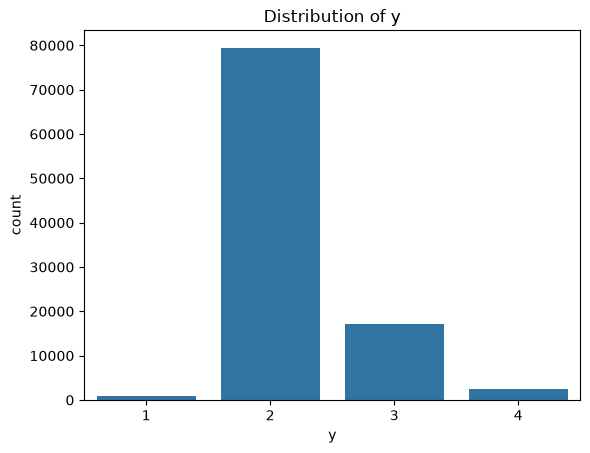

In [76]:
# y distribution

sns.countplot(x='y', data=df)
plt.title('Distribution of y')
plt.show()

In [77]:

target_col = "y"


numeric_cols = ["f3", "f4", "f5", "f14", "f15", "f16", "f17", "f18", "f20"]


datetime_cols = ["f2", "f13"]

bool_cols = ["f22", "f23", "f24", "f25", "f26", "f27", "f28", "f29", "f30", "f31", "f32"]

cat_cols = [col for col in df.columns if col not in numeric_cols + datetime_cols + bool_cols + [target_col]]

print("Numerical:", numeric_cols)
print("Datetime:", datetime_cols)
print("Boolean:", bool_cols)
print("Categorical/Text:", cat_cols)

# numeric features
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# y
df[target_col] = pd.to_numeric(df[target_col], errors="coerce")

# T/F to 1/0
for col in bool_cols:
    df[col] = df[col].astype(str).str.upper().map({
        "TRUE": 1,
        "FALSE": 0
    })
    
for col in bool_cols:
    print("\n", col)
    print(df[col].value_counts(dropna=False))

#datetime
for col in datetime_cols:
    df[col] = pd.to_datetime(df[col], errors="coerce")
    
    
    

Numerical: ['f3', 'f4', 'f5', 'f14', 'f15', 'f16', 'f17', 'f18', 'f20']
Datetime: ['f2', 'f13']
Boolean: ['f22', 'f23', 'f24', 'f25', 'f26', 'f27', 'f28', 'f29', 'f30', 'f31', 'f32']
Categorical/Text: ['f1', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11', 'f12', 'f19', 'f21', 'f33', 'f34']

 f22
f22
0    98821
1     1179
Name: count, dtype: int64

 f23
f23
0    88734
1    11266
Name: count, dtype: int64

 f24
f24
0    99494
1      506
Name: count, dtype: int64

 f25
f25
0    92562
1     7438
Name: count, dtype: int64

 f26
f26
0    99760
1      240
Name: count, dtype: int64

 f27
f27
0    99078
1      922
Name: count, dtype: int64

 f28
f28
0    99998
1        2
Name: count, dtype: int64

 f29
f29
0    97376
1     2624
Name: count, dtype: int64

 f30
f30
0    97229
1     2771
Name: count, dtype: int64

 f31
f31
0    85277
1    14723
Name: count, dtype: int64

 f32
f32
0    100000
Name: count, dtype: int64


### 3.4.2

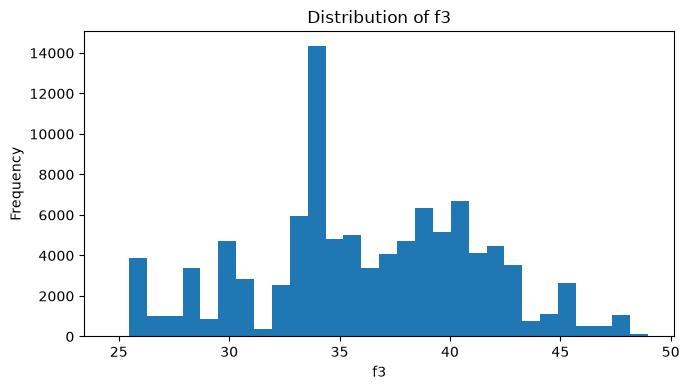

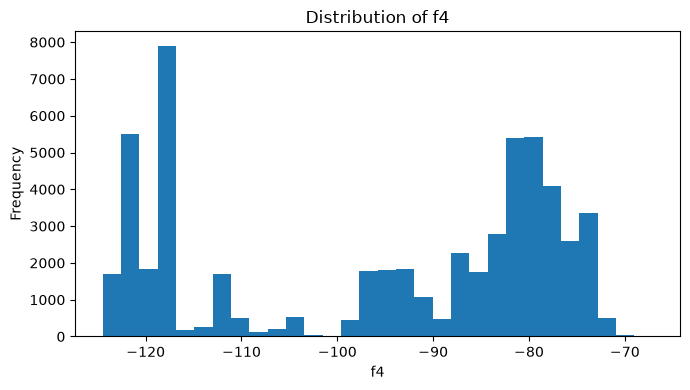

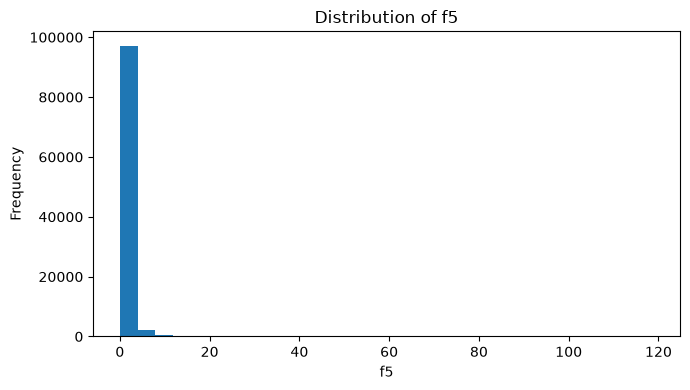

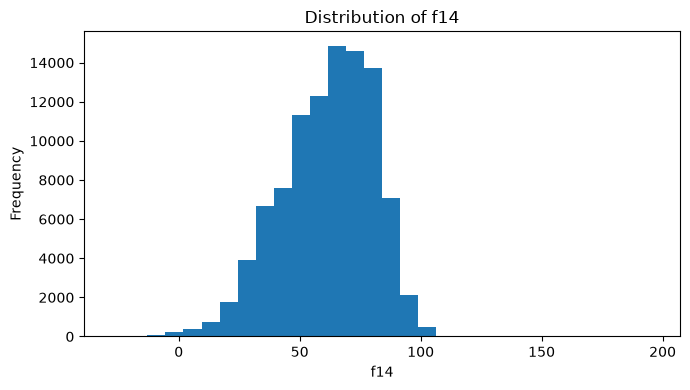

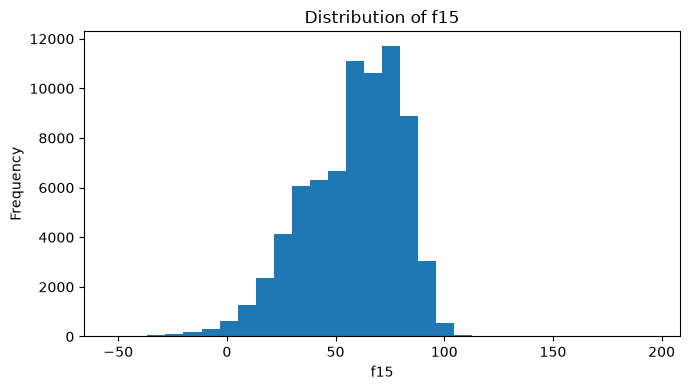

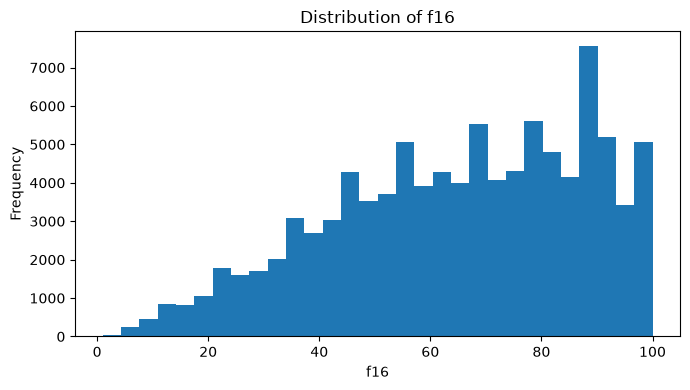

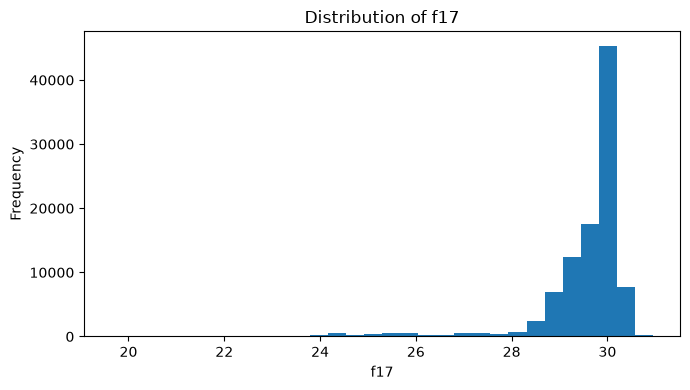

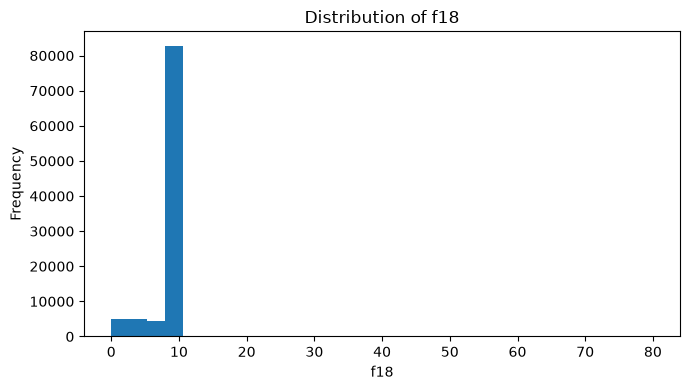

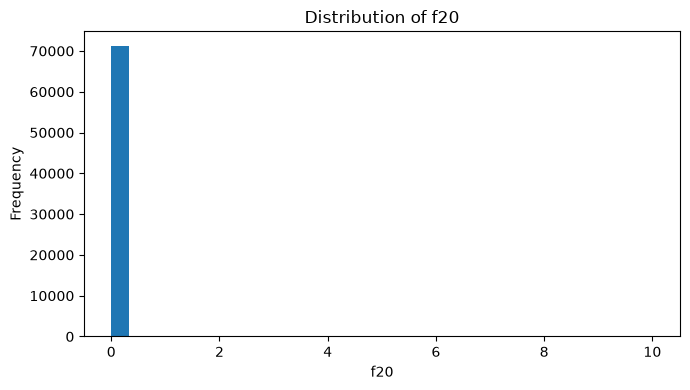

In [78]:
for col in numeric_cols:
    plt.figure(figsize=(7, 4))
    plt.hist(df[col].dropna(), bins=30)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()
    

C:\Users\av laptop\AppData\Local\Temp\ipykernel_14968\3399939011.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False)


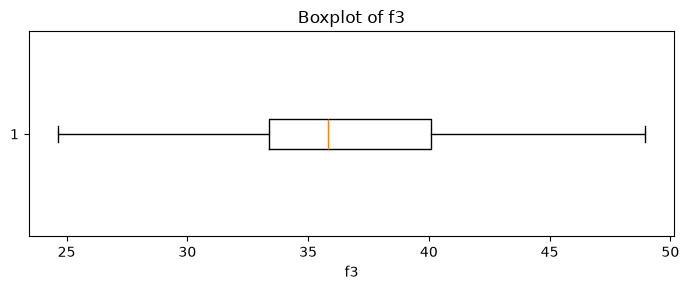

C:\Users\av laptop\AppData\Local\Temp\ipykernel_14968\3399939011.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False)


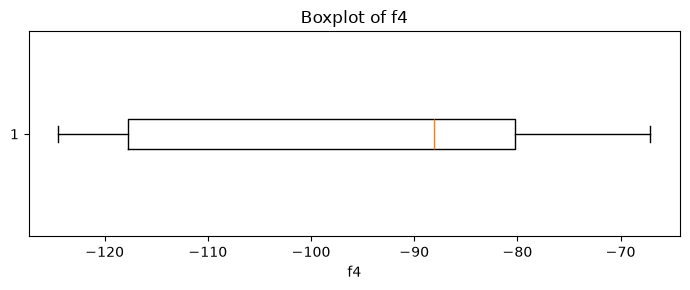

C:\Users\av laptop\AppData\Local\Temp\ipykernel_14968\3399939011.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False)


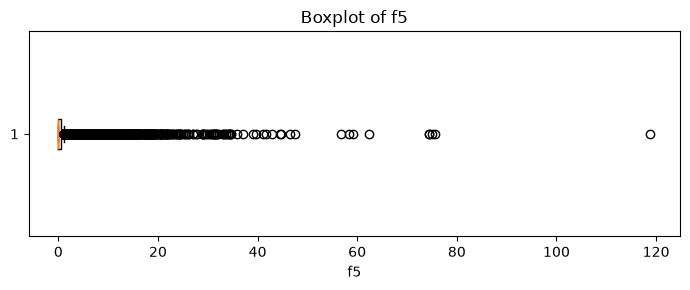

C:\Users\av laptop\AppData\Local\Temp\ipykernel_14968\3399939011.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False)


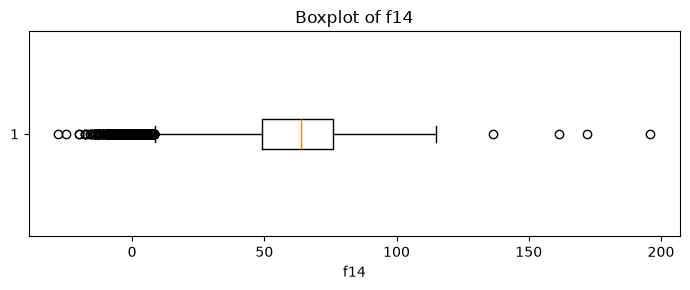

C:\Users\av laptop\AppData\Local\Temp\ipykernel_14968\3399939011.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False)


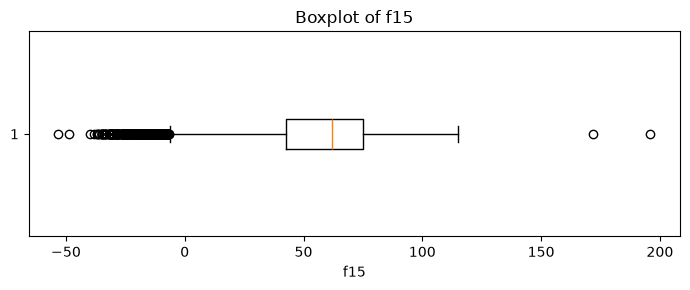

C:\Users\av laptop\AppData\Local\Temp\ipykernel_14968\3399939011.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False)


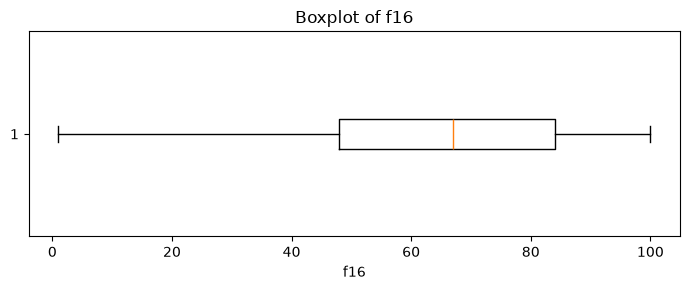

C:\Users\av laptop\AppData\Local\Temp\ipykernel_14968\3399939011.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False)


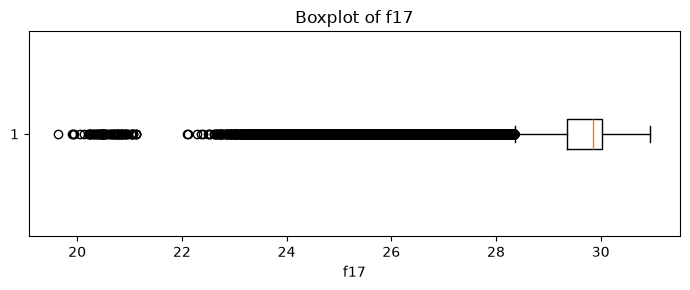

C:\Users\av laptop\AppData\Local\Temp\ipykernel_14968\3399939011.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False)


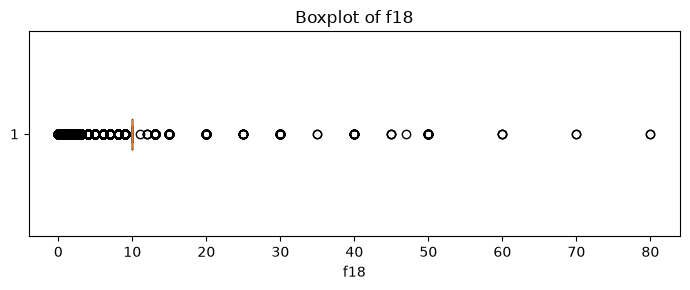

C:\Users\av laptop\AppData\Local\Temp\ipykernel_14968\3399939011.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False)


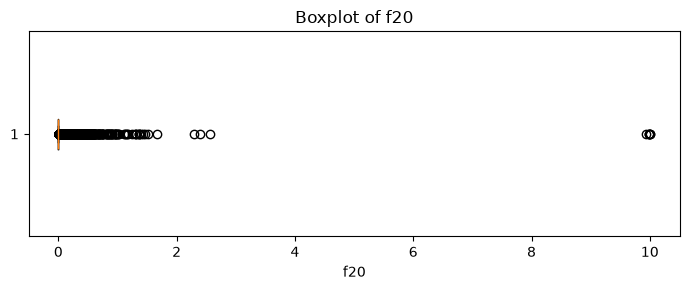

In [79]:
# boxplot of numerical features

for col in numeric_cols:
    plt.figure(figsize=(7, 3))
    plt.boxplot(df[col].dropna(), vert=False)
    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()

### 3.4.3

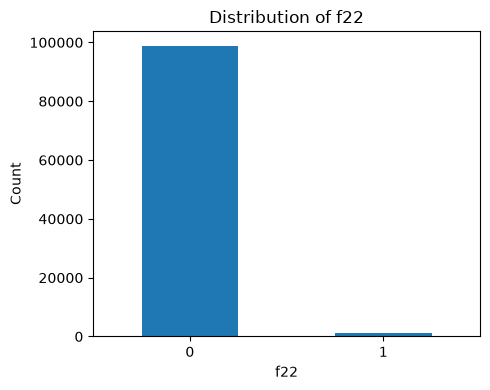

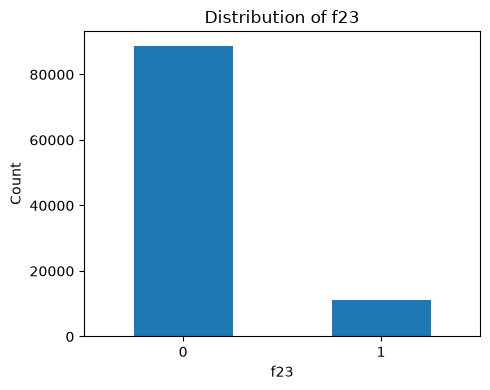

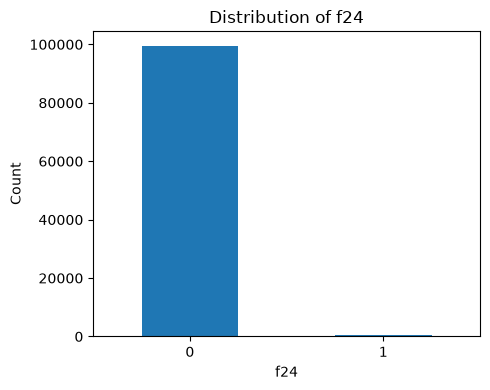

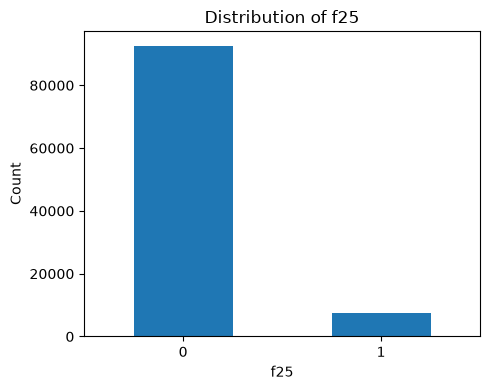

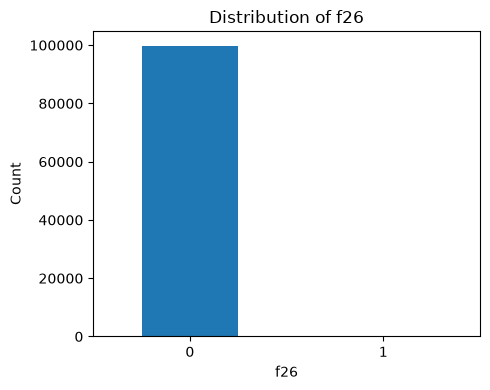

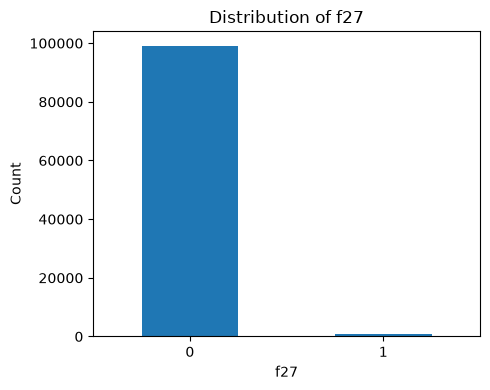

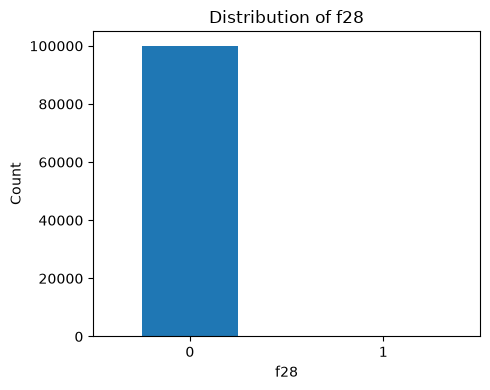

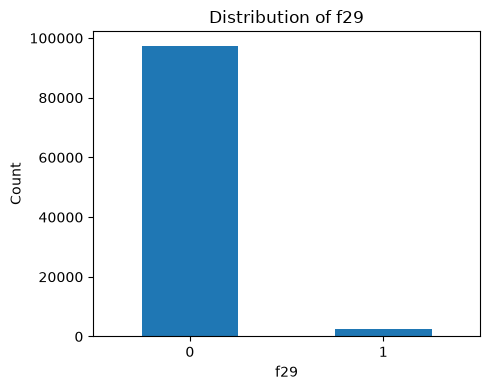

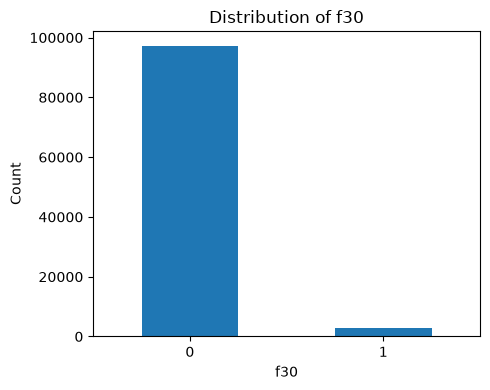

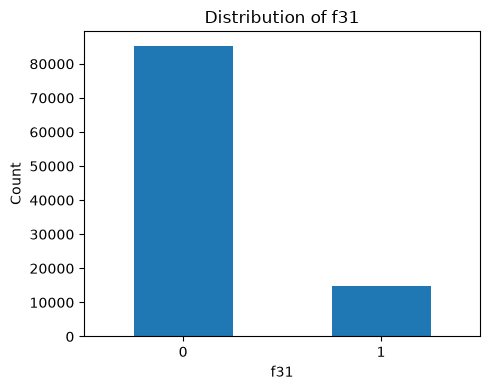

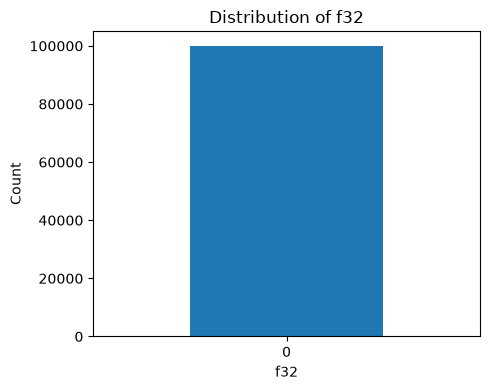

In [80]:
# distribution boolean features

for col in bool_cols:
    plt.figure(figsize=(5, 4))
    df[col].value_counts(dropna=False).sort_index().plot(kind="bar")
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

### 3.4.4


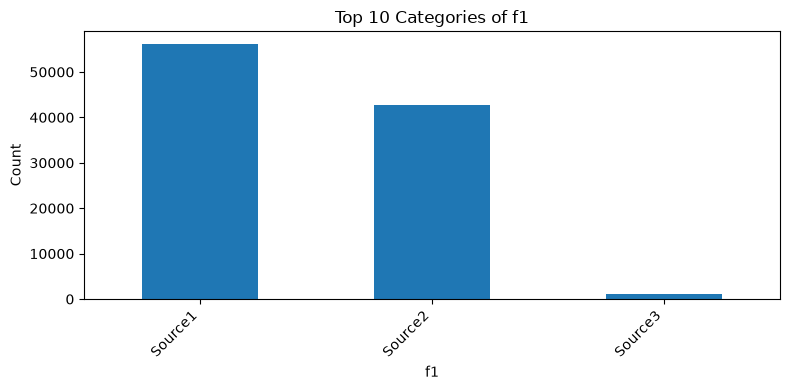

C:\Users\av laptop\AppData\Local\Temp\ipykernel_14968\2554597594.py:11: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


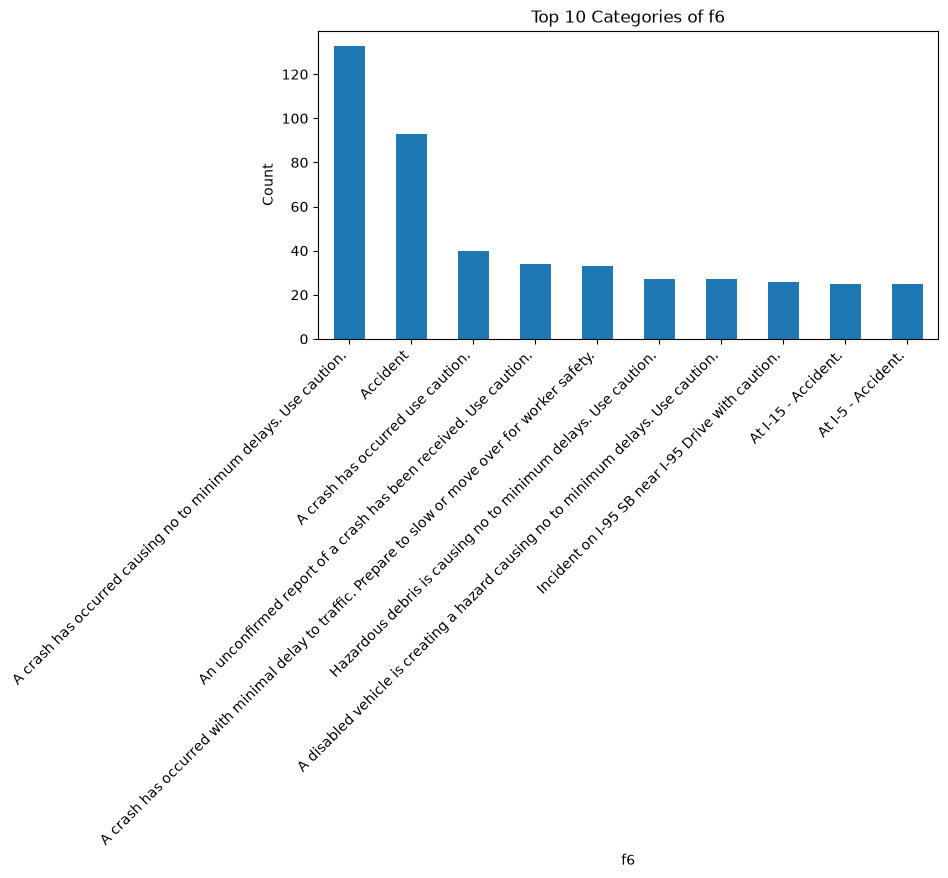

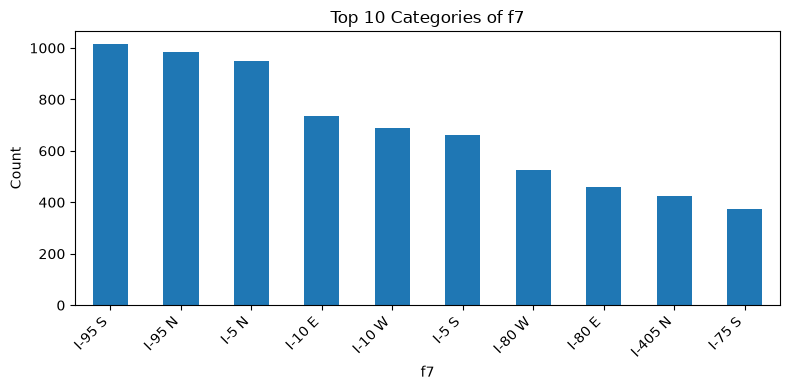

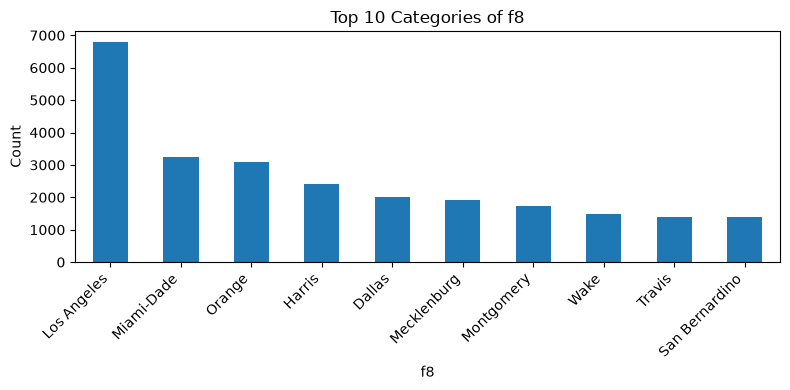

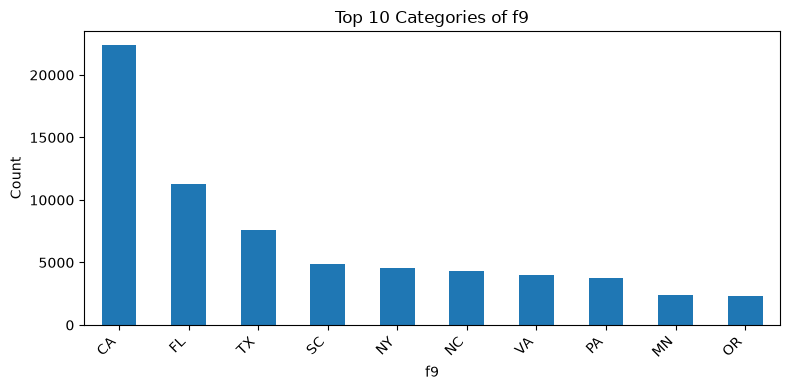

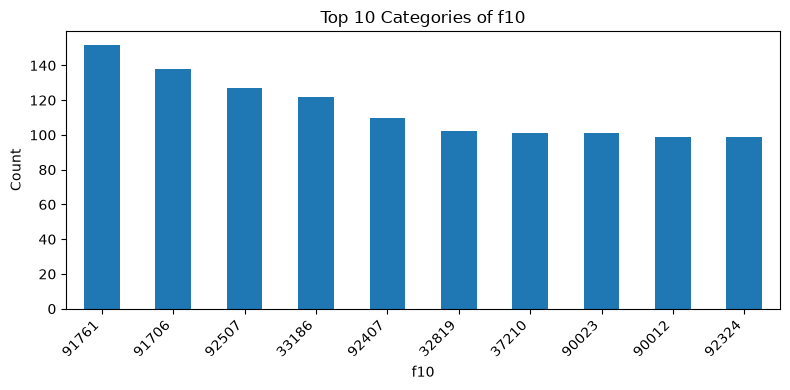

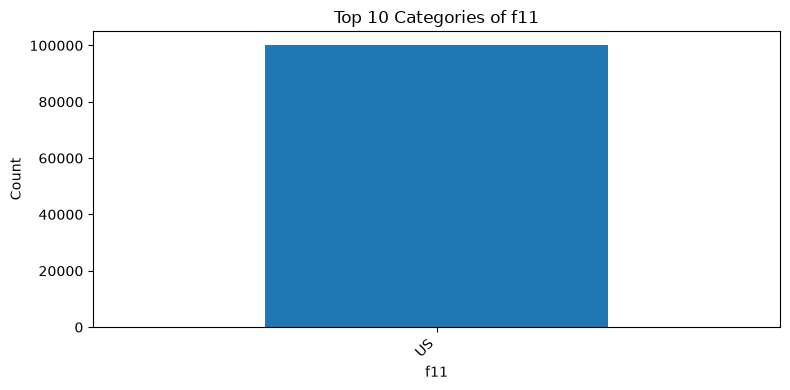

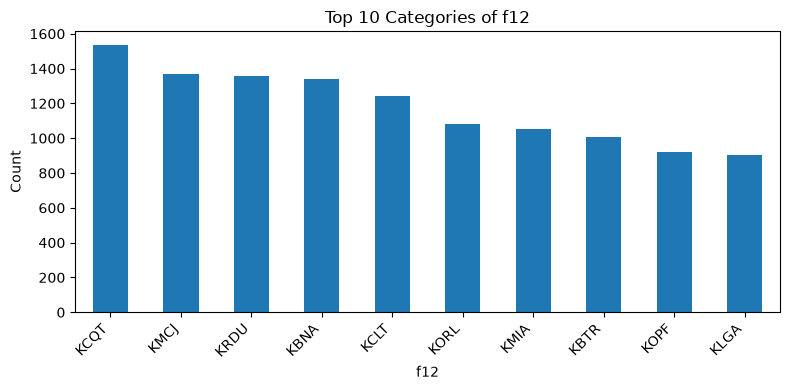

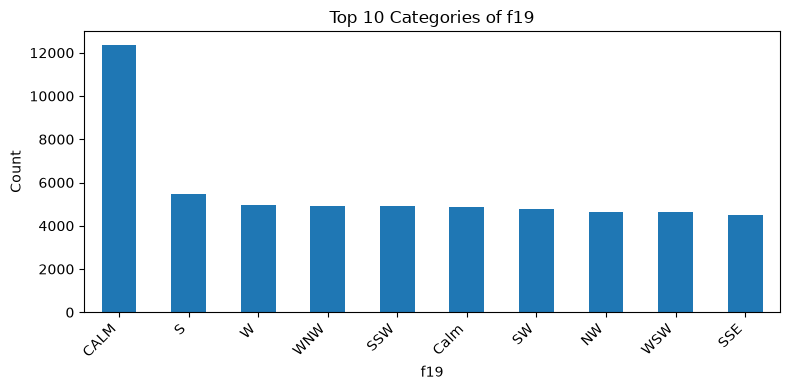

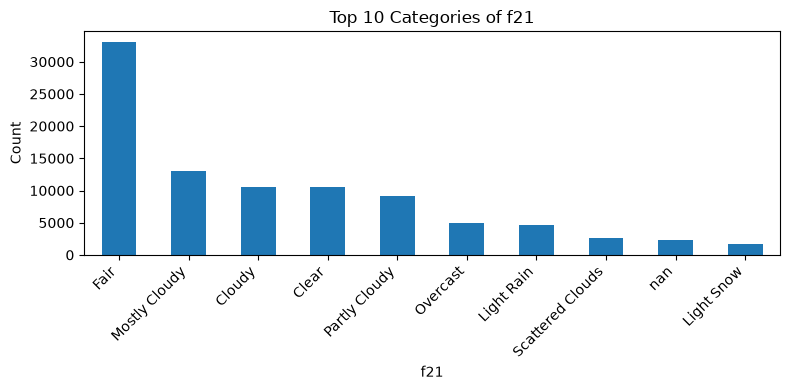

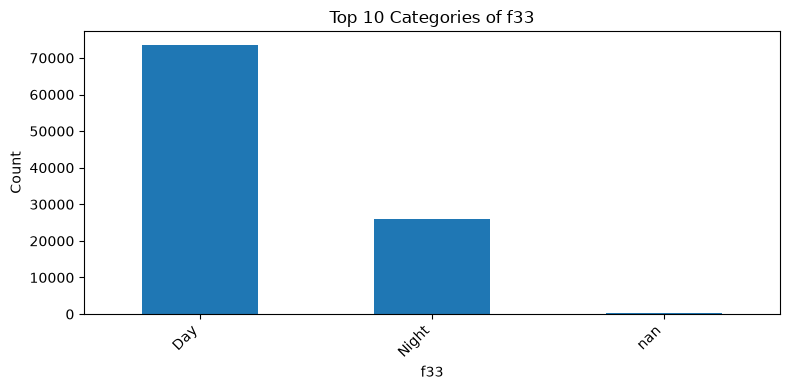

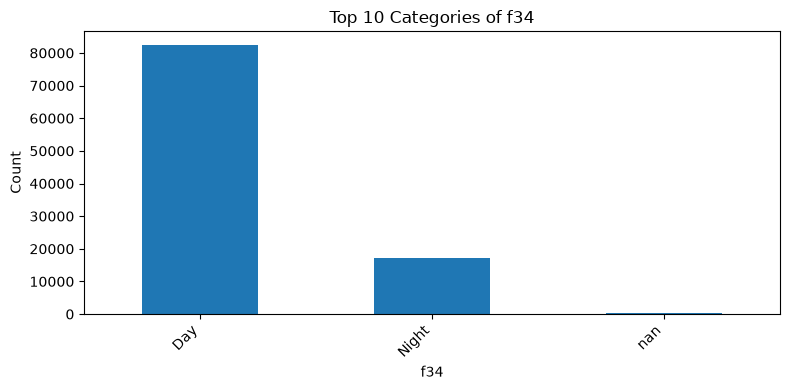

In [81]:
# distribution of categorical features

for col in cat_cols:
    
    plt.figure(figsize=(8, 4))
    df[col].astype(str).value_counts().head(10).plot(kind="bar")
    plt.title(f"Top 10 Categories of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

## **3.5 Outliners and Missing Values**

## 3.5.1 Missing values

In [82]:
#table

missing_count = df.isna().sum()
missing_percent = df.isna().mean() * 100

missing_table = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percent": missing_percent
}).sort_values(by="Missing Percent", ascending=False)

missing_table.head(20)



,Missing Count,Missing Percent
f4,43861,43.861
f20,28484,28.484
f15,25937,25.937
f2,9668,9.668
f19,2285,2.285
f18,2279,2.279
f21,2240,2.240
f16,2233,2.233
f14,2115,2.115
f17,1823,1.823


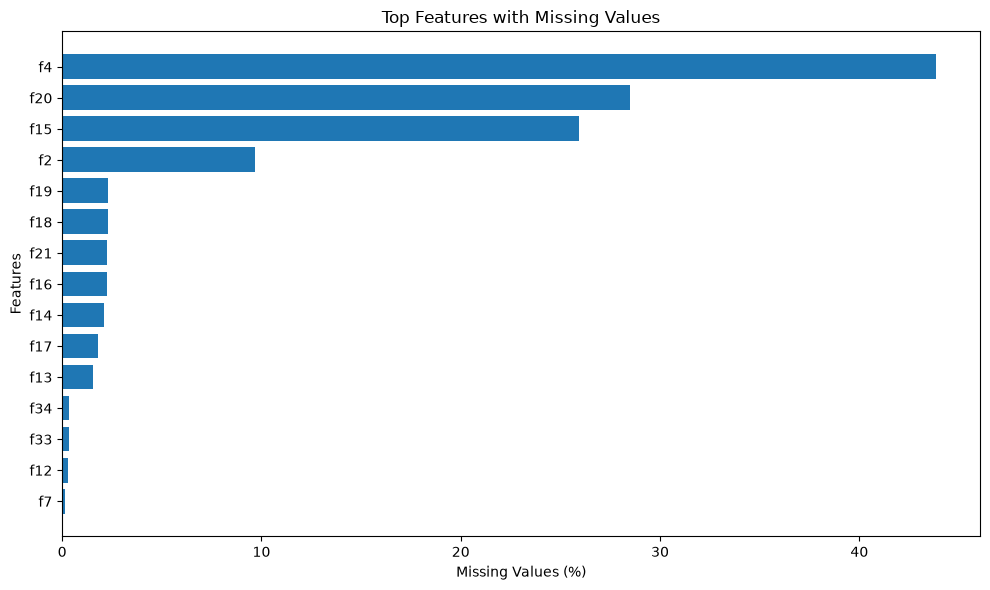

In [83]:
#plot

top_missing = missing_table[missing_table["Missing Count"] > 0].head(15)

plt.figure(figsize=(10, 6))
plt.barh(top_missing.index[::-1], top_missing["Missing Percent"][::-1])
plt.xlabel("Missing Values (%)")
plt.ylabel("Features")
plt.title("Top Features with Missing Values")
plt.tight_layout()
plt.show()

## 3.5.2 Outliners

In [84]:
numeric_cols = [
    "f3",   
    "f4",   
    "f5",   
    "f14",  
    "f15",  
    "f16",  
    "f17",  
    "f18",  
    "f20"    
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce") #convert all entries to num e.g. if there is "245" --> 245. if has miss data and detected an obj there were no error and convert to NAH
    

#IQR
    
outlier_summary = []

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    
    outlier_summary.append({
        "Feature": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers),
        "Outlier Percent": len(outliers) / len(df) * 100
    })

outlier_table = pd.DataFrame(outlier_summary)
outlier_table.sort_values(by="Outlier Percent", ascending=False)

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percent
7,f18,10.000000,10.000000,0.000000,10.000000,10.000000,19266,19.266
2,f5,0.000000,0.466000,0.466000,-0.699000,1.165000,12558,12.558
8,f20,0.000000,0.000000,0.000000,0.000000,0.000000,6993,6.993
6,f17,29.360000,30.030000,0.670000,28.355000,31.035000,5680,5.680
3,f14,49.000000,76.000000,27.000000,8.500000,116.500000,644,0.644
4,f15,42.500000,75.000000,32.500000,-6.250000,123.750000,503,0.503
0,f3,33.392145,40.095038,6.702893,23.337806,50.149377,0,0.000
1,f4,-117.720860,-80.250395,37.470464,-173.926557,-24.044699,0,0.000
5,f16,48.000000,84.000000,36.000000,-6.000000,138.000000,0,0.000


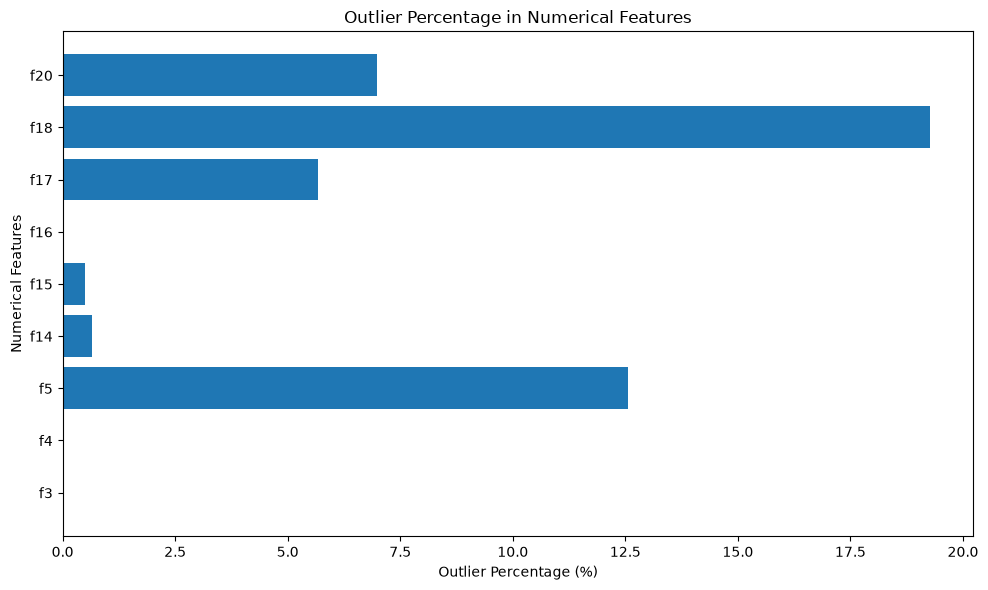

In [85]:
#plot

plt.figure(figsize=(10, 6))
plt.barh(outlier_table["Feature"], outlier_table["Outlier Percent"])
plt.xlabel("Outlier Percentage (%)")
plt.ylabel("Numerical Features")
plt.title("Outlier Percentage in Numerical Features")
plt.tight_layout()
plt.show()

C:\Users\av laptop\AppData\Local\Temp\ipykernel_14968\169039108.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False)


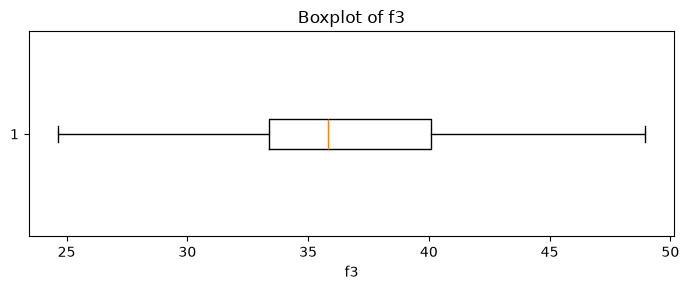

C:\Users\av laptop\AppData\Local\Temp\ipykernel_14968\169039108.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False)


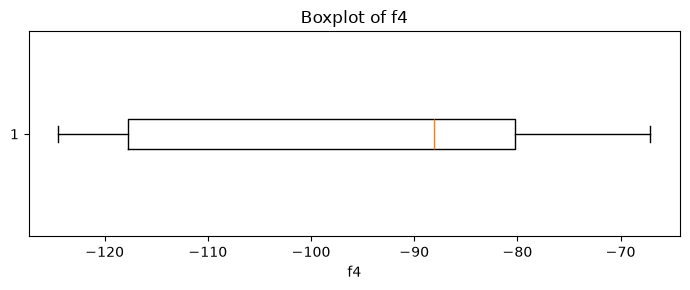

C:\Users\av laptop\AppData\Local\Temp\ipykernel_14968\169039108.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False)


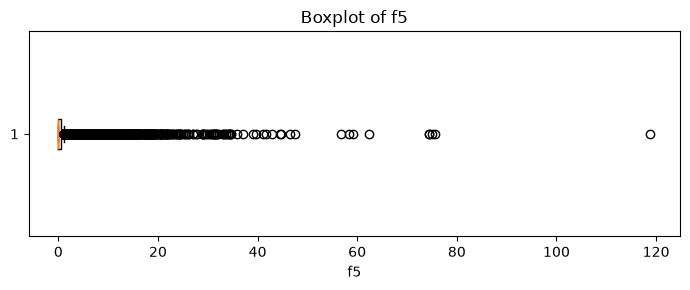

C:\Users\av laptop\AppData\Local\Temp\ipykernel_14968\169039108.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False)


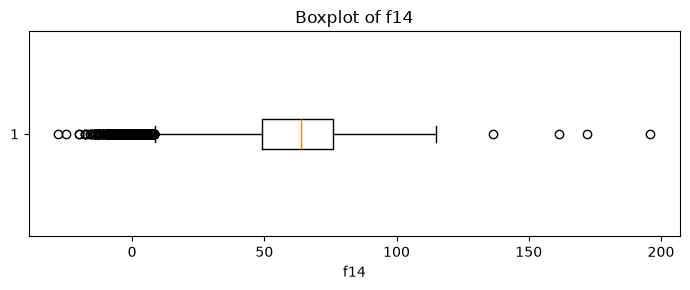

C:\Users\av laptop\AppData\Local\Temp\ipykernel_14968\169039108.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False)


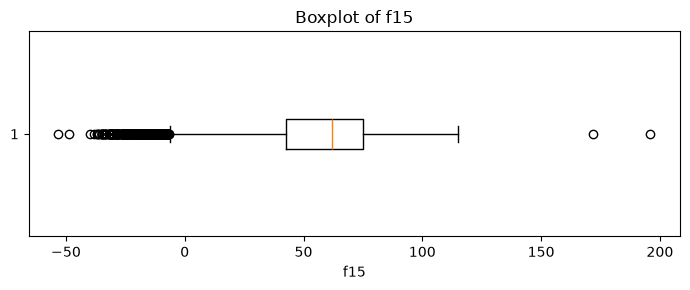

C:\Users\av laptop\AppData\Local\Temp\ipykernel_14968\169039108.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False)


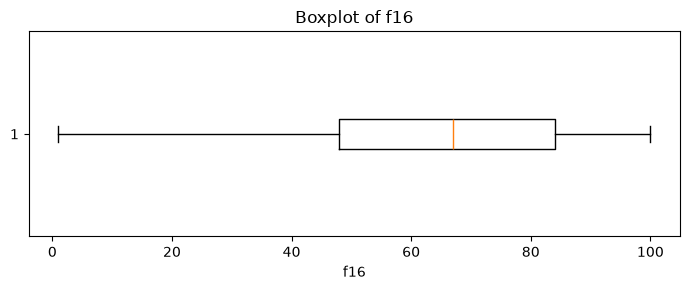

C:\Users\av laptop\AppData\Local\Temp\ipykernel_14968\169039108.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False)


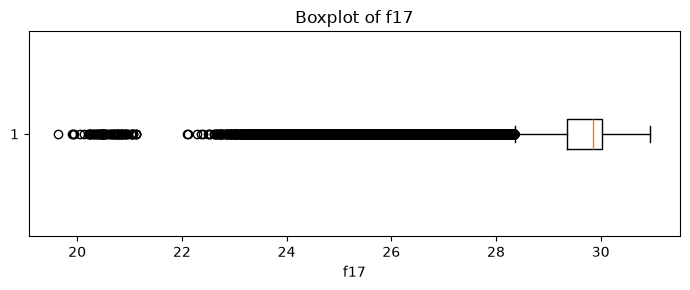

C:\Users\av laptop\AppData\Local\Temp\ipykernel_14968\169039108.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False)


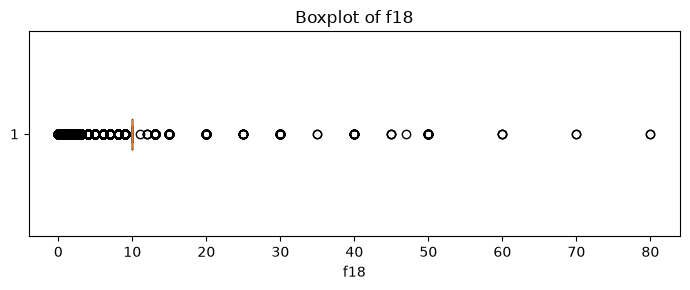

C:\Users\av laptop\AppData\Local\Temp\ipykernel_14968\169039108.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False)


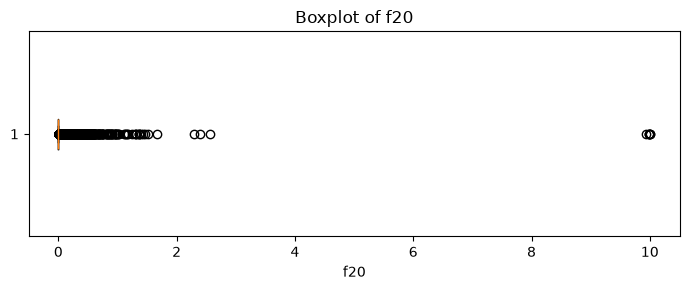

In [86]:
#Boxplot

for col in numeric_cols:
    plt.figure(figsize=(7, 3))
    plt.boxplot(df[col].dropna(), vert=False)
    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()

# **4. Cleaning and Preprocessing**

## 4.1 Deduplication

In [87]:
# number of duplicated rows
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

# remove duplicate

df_cleaned = df.drop_duplicates()

print("Shape before removing duplicates:", df.shape)
print("Shape after removing duplicates:", df_cleaned.shape)

# check for ni duplication

duplicate_count = df_cleaned.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)
if  duplicate_count == 0:
    print("Deduplication successfully apllied")
    
    
    
# update the DataFrame
    
df = df_cleaned


Number of duplicate rows: 25
Shape before removing duplicates: (100000, 35)
Shape after removing duplicates: (99975, 35)
Number of duplicate rows: 0
Deduplication successfully apllied


## 4.2. Handling Missing Values

### 4.2.1. Numerical Values

In [88]:
#in 3.4. ditribution ; each data type col was coded no need to do it again

for col in numeric_cols:
    median_value = df[col].median()
    df[col] = df[col].fillna(median_value)

df[numeric_cols].isna().sum()

f3     0
f4     0
f5     0
f14    0
f15    0
f16    0
f17    0
f18    0
f20    0
dtype: int64

### 4.2.2. Categorical Values

In [89]:
for col in cat_cols:
    df[col] = df[col].fillna("Unknown")
    
df[cat_cols].isna().sum()

f1     0
f6     0
f7     0
f8     0
f9     0
f10    0
f11    0
f12    0
f19    0
f21    0
f33    0
f34    0
dtype: int64

### 4.2.3. boolean Values

In [90]:
for col in bool_cols:
    mode_value = df[col].mode()[0]
    df[col] = df[col].fillna(mode_value)
    
df[bool_cols].isna().sum()

f22    0
f23    0
f24    0
f25    0
f26    0
f27    0
f28    0
f29    0
f30    0
f31    0
f32    0
dtype: int64

### 4.2.4. Date and Time

In [91]:
for col in datetime_cols:
    
    # in 3.4. dist the f2 and f13 were coverted to datetime class
    df[col + "_hour"] = df[col].dt.hour
    df[col + "_month"] = df[col].dt.month
    df[col + "_dayofweek"] = df[col].dt.dayofweek
    
    
    
time_features = []

for col in datetime_cols:
    time_features.extend([
        col + "_hour",
        col + "_month",
        col + "_dayofweek"
    ])

for col in time_features:
    df[col] = df[col].fillna(df[col].mode()[0])
    
    
    
df = df.drop(columns=datetime_cols)

df.shape

(99975, 39)

In [92]:
df.head()

,f1,f3,f4,f5,f6,f7,f8,f9,f10,f11,...,f32,f33,f34,y,f2_hour,f2_month,f2_dayofweek,f13_hour,f13_month,f13_dayofweek
0,Source1,34.028059,-118.196987,0.610,Accident on Whittier Blvd (CA-60) from Lorena ...,CA-60 E,Los Angeles,CA,90023,US,...,0,Day,Day,2,14.0,5.0,5.0,12.0,5.0,5.0
1,Source1,33.894340,-80.183103,0.183,Incident on MYRTLE BEACH HWY near DAFFODIL LN ...,Myrtle Beach Hwy,Sumter,SC,29153-8896,US,...,0,Night,Day,2,18.0,12.0,4.0,6.0,12.0,3.0
2,Source1,41.736997,-72.757589,1.089,ConnDOT: Crash (2 Vehicle) on I-84 Westbound b...,I-84 W,Hartford,CT,6110,US,...,0,Day,Day,2,16.0,2.0,2.0,15.0,2.0,2.0
3,Source2,42.339859,-88.038530,0.000,Accident on Summer St near Power House St.,Summer St,Suffolk,MA,02127-1610,US,...,0,Day,Day,2,16.0,10.0,4.0,15.0,10.0,4.0
4,Source2,28.468746,-88.038530,0.000,Right lane blocked due to multi-vehicle accide...,I-4 E,Orange,FL,32819,US,...,0,Day,Day,3,16.0,2.0,1.0,15.0,2.0,1.0


## 4.3. no need code

## 4.4. Converting textual or categorical data into numerical format

In [93]:
#frequnt of cardinality od cat

for col in cat_cols:
    print(col, "unique values:", df[col].nunique())

f1 unique values: 3
f6 unique values: 92556
f7 unique values: 32612
f8 unique values: 1298
f9 unique values: 49
f10 unique values: 36945
f11 unique values: 1
f12 unique values: 1618
f19 unique values: 25
f21 unique values: 87
f33 unique values: 3
f34 unique values: 3


In [94]:
# division of categorial feature into low_cardinality_cols and high_cardinality_cols

low_cardinality_cols = []
high_cardinality_cols = []

for col in cat_cols:
    unique_count = df[col].nunique()
    
    if unique_count <= 10:
        low_cardinality_cols.append(col)
    else:
        high_cardinality_cols.append(col)
        


print("Low-cardinality:", low_cardinality_cols)
high_cardinality_cols.remove("f6")  #in markdown
high_cardinality_cols_non_text = high_cardinality_cols
print("High-cardinality:", high_cardinality_cols_non_text)

Low-cardinality: ['f1', 'f11', 'f33', 'f34']
High-cardinality: ['f7', 'f8', 'f9', 'f10', 'f12', 'f19', 'f21']


f6 has 92000 cardinas so it should be handel by NLP algorithm because it is description and its done in Feature Extraction

### 4.4.1. One hot encoding for low cardinality 

In [95]:
#one hot encoding for low_cardinality_cols whit drop one

df = pd.get_dummies(
    df,
    columns=low_cardinality_cols,
    drop_first=True
)


In [96]:
df.shape
df.head()

# why 41 cols? f1-->2 / f11-->0 / f34-->2 / f33-->2  39-4(1)+2+0+2+2 = 41

,f3,f4,f5,f6,f7,f8,f9,f10,f12,f14,...,f2_dayofweek,f13_hour,f13_month,f13_dayofweek,f1_Source2,f1_Source3,f33_Night,f33_Unknown,f34_Night,f34_Unknown
0,34.028059,-118.196987,0.610,Accident on Whittier Blvd (CA-60) from Lorena ...,CA-60 E,Los Angeles,CA,90023,KCQT,66.0,...,5.0,12.0,5.0,5.0,False,False,False,False,False,False
1,33.894340,-80.183103,0.183,Incident on MYRTLE BEACH HWY near DAFFODIL LN ...,Myrtle Beach Hwy,Sumter,SC,29153-8896,KSMS,55.0,...,4.0,6.0,12.0,3.0,False,False,True,False,False,False
2,41.736997,-72.757589,1.089,ConnDOT: Crash (2 Vehicle) on I-84 Westbound b...,I-84 W,Hartford,CT,6110,KHFD,43.0,...,2.0,15.0,2.0,2.0,False,False,False,False,False,False
3,42.339859,-88.038530,0.000,Accident on Summer St near Power House St.,Summer St,Suffolk,MA,02127-1610,KBOS,57.0,...,4.0,15.0,10.0,4.0,True,False,False,False,False,False
4,28.468746,-88.038530,0.000,Right lane blocked due to multi-vehicle accide...,I-4 E,Orange,FL,32819,KMCO,78.1,...,1.0,15.0,2.0,1.0,True,False,False,False,False,False


### 4.4.2. Frequency Encoding

for high_cardinality_cols_non_text

In [97]:
for col in high_cardinality_cols_non_text:
    if col in df.columns:
        freq_map = df[col].value_counts(normalize=True)
        df[col + "_freq"] = df[col].map(freq_map)
        df = df.drop(columns=[col])

### 4.4.3. TF-IDF
done in Feature Extraction

In [98]:
df.shape

(99975, 41)

## 4.5. Splitting the data into training and testing sets

In [99]:
from sklearn.model_selection import train_test_split

target_col = "y"

X = df.drop(columns=[target_col])
y = df[target_col]

# First split: 80% train,20% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=33,
    stratify=y
)

# second split:10% validation, 10% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.5,
    random_state=23,
    stratify=y_temp
)

print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("X_test shape:", X_test.shape)

print("y_train distribution:")
print(y_train.value_counts(normalize=True))

print("y_val distribution:")
print(y_val.value_counts(normalize=True))

print("y_test distribution:")
print(y_test.value_counts(normalize=True))

X_train shape: (79980, 40)
X_val shape: (9997, 40)
X_test shape: (9998, 40)
y_train distribution:
y
2    0.794099
3    0.171155
4    0.025781
1    0.008965
Name: proportion, dtype: float64
y_val distribution:
y
2    0.794138
3    0.171151
4    0.025808
1    0.008903
Name: proportion, dtype: float64
y_test distribution:
y
2    0.794059
3    0.171134
4    0.025805
1    0.009002
Name: proportion, dtype: float64


## 4.6. Normalizing or standardizing features
Later on Feature extraction

## **5. Feature Engineering**

### **5.1. Feature Extraction**

### 5.1.1. f6 TF-IDF

In [100]:
# from sklearn.feature_extraction.text import TfidfVectorizer
# import pandas as pd

# text_col = "f6"

# tfidf = TfidfVectorizer(
#     max_features=50,
#     stop_words="english"
# )

# X_train_tfidf_matrix = tfidf.fit_transform(X_train[text_col].fillna("Unknown"))

# X_val_tfidf_matrix = tfidf.transform(X_val[text_col].fillna("Unknown"))
# X_test_tfidf_matrix = tfidf.transform(X_test[text_col].fillna("Unknown"))

# tfidf_cols = [f"{text_col}_tfidf_{word}" for word in tfidf.get_feature_names_out()]

# X_train_tfidf = pd.DataFrame(
#     X_train_tfidf_matrix.toarray(),
#     columns=tfidf_cols,
#     index=X_train.index
# )

# X_val_tfidf = pd.DataFrame(
#     X_val_tfidf_matrix.toarray(),
#     columns=tfidf_cols,
#     index=X_val.index
# )

# X_test_tfidf = pd.DataFrame(
#     X_test_tfidf_matrix.toarray(),
#     columns=tfidf_cols,
#     index=X_test.index
# )

# X_train = X_train.drop(columns=[text_col])
# X_val = X_val.drop(columns=[text_col])
# X_test = X_test.drop(columns=[text_col])

# X_train = pd.concat([X_train, X_train_tfidf], axis=1)
# X_val = pd.concat([X_val, X_val_tfidf], axis=1)
# X_test = pd.concat([X_test, X_test_tfidf], axis=1)

### 5.1.2
no need

### 5.1.3

no need

## 5.2. Feature Normalize or Scaling

befor scaling data exported for embedde methos like DS , RF , XGboost beacause these mehods are not sensitive to scaling

In [ ]:
# ===============================
# Export data for Embedded Methods
# Before Scaling
# ===============================

import os

folder = "Data Export Embedded Methods"

os.makedirs(folder, exist_ok=True)


#f6 was excluded:

numeric_cols = X_train.select_dtypes(include=["number", "bool"]).columns.tolist()



# Save numerical features before scaling
X_train[numeric_cols].to_csv(
    folder + "/X_train_embedded.csv",
    index=False
)

X_val[numeric_cols].to_csv(
    folder + "/X_val_embedded.csv",
    index=False
)

X_test[numeric_cols].to_csv(
    folder + "/X_test_embedded.csv",
    index=False)


# Save target
y_train.to_csv(
    folder + "/y_train.csv",
    index=False
)

y_val.to_csv(
    folder + "/y_val.csv",
    index=False
)

y_test.to_csv(
    folder + "/y_test.csv",
    index=False
)


print("Embedded method data exported successfully!")

Embedded method data exported successfully!


In [102]:
from sklearn.preprocessing import StandardScaler


text_col = "f6"



scaler = StandardScaler()


X_train_scaled_numeric = scaler.fit_transform(X_train[numeric_cols])
X_val_scaled_numeric = scaler.transform(X_val[numeric_cols])
X_test_scaled_numeric = scaler.transform(X_test[numeric_cols])


X_train_scaled_numeric = pd.DataFrame(
    X_train_scaled_numeric,
    columns=numeric_cols,
    index=X_train.index
)

X_val_scaled_numeric = pd.DataFrame(
    X_val_scaled_numeric,
    columns=numeric_cols,
    index=X_val.index
)

X_test_scaled_numeric = pd.DataFrame(
    X_test_scaled_numeric,
    columns=numeric_cols,
    index=X_test.index
)

In [103]:
X_train_scaled_numeric["f16"].describe

X_train.shape

(79980, 40)

## 5.3 no need

## 5.4. Feature Selection


In [104]:
X_test_scaled_numeric.shape

(9998, 39)

In [105]:
non_numeric_cols = X_train_scaled_numeric.select_dtypes(exclude=["number", "bool"]).columns
print(non_numeric_cols)


Index([], dtype='object')


### 5.4.1 Filter Method

### 5.4.1.1. Mutual Information

In [106]:
from sklearn.feature_selection import mutual_info_classif

mi_scores = mutual_info_classif(X_train_scaled_numeric, y_train, random_state=42)

mi_df = pd.DataFrame({
    "Feature": X_train_scaled_numeric.columns,
    "Mutual Information": mi_scores
}).sort_values(by="Mutual Information", ascending=False)

mi_df.head(25)

,Feature,Mutual Information
1,f4,0.116595
2,f5,0.094825
26,f1_Source2,0.092381
0,f3,0.077598
33,f8_freq,0.054413
32,f7_freq,0.047180
36,f12_freq,0.045662
35,f10_freq,0.042515
34,f9_freq,0.030484
4,f15,0.029735


### 5.4.1.2. Fisher Score

In [107]:

def fisher_score_classification(X, y):
    X = pd.DataFrame(X)
    y = np.array(y)

    classes = np.unique(y)
    scores = []

    for col in X.columns:
        x = X[col].values
        overall_mean = np.mean(x)

        numerator = 0
        denominator = 0

        for c in classes:
            x_c = x[y == c]
            n_c = len(x_c)

            if n_c == 0:
                continue

            class_mean = np.mean(x_c)
            class_var = np.var(x_c)

            numerator += n_c * (class_mean - overall_mean) ** 2
            denominator += n_c * class_var

        score = numerator / denominator if denominator != 0 else 0
        scores.append(score)

    return np.array(scores)


fisher_scores = fisher_score_classification(X_train_scaled_numeric, y_train)

fisher_df = pd.DataFrame({
    "Feature": X_train_scaled_numeric.columns,
    "Fisher Score": fisher_scores
}).sort_values(by="Fisher Score", ascending=False)

fisher_df.head(25)

,Feature,Fisher Score
26,f1_Source2,0.191736
32,f7_freq,0.031999
35,f10_freq,0.027100
38,f21_freq,0.022139
1,f4,0.017781
10,f23,0.014817
18,f31,0.014398
37,f19_freq,0.010681
2,f5,0.010275
34,f9_freq,0.009305


### 5.4.2. Wrapper Methods
no need


### 5.4.3. Embedded Methos
Later on model training


### 5.4.4 Select feature
base on filter methos

In [108]:
ranking_df = pd.merge(
    fisher_df,
    mi_df,
    on="Feature",
    how="inner"
)

ranking_df["Fisher Rank"] = ranking_df["Fisher Score"].rank(
    ascending=False,
    method="min"
)

ranking_df["MI Rank"] = ranking_df["Mutual Information"].rank(
    ascending=False,
    method="min"
)

ranking_df["Average Rank"] = ranking_df[
    ["Fisher Rank", "MI Rank"]
].mean(axis=1)

ranking_df = ranking_df.sort_values(by="Average Rank")

ranking_df.head(25)

,Feature,Fisher Score,Mutual Information,Fisher Rank,MI Rank,Average Rank
0,f1_Source2,0.191736,0.092381,1.0,3.0,2.0
4,f4,0.017781,0.116595,5.0,1.0,3.0
1,f7_freq,0.031999,0.047180,2.0,6.0,4.0
2,f10_freq,0.027100,0.042515,3.0,8.0,5.5
8,f5,0.010275,0.094825,9.0,2.0,5.5
3,f21_freq,0.022139,0.025476,4.0,11.0,7.5
10,f12_freq,0.007723,0.045662,11.0,7.0,9.0
9,f9_freq,0.009305,0.030484,10.0,9.0,9.5
13,f8_freq,0.005105,0.054413,14.0,5.0,9.5
15,f3,0.004803,0.077598,16.0,4.0,10.0


### Export the filter base selected feature

In [109]:
import pandas as pd
import os

ranking_df = ranking_df.sort_values(by="Average Rank").reset_index(drop=True)

selected_features = ranking_df.head(25)["Feature"].tolist()

selected_features_df = ranking_df.head(25).copy()

print("Selected Features:")
print(selected_features)


X_train_selected = X_train_scaled_numeric[selected_features].copy()
X_val_selected = X_val_scaled_numeric[selected_features].copy()
X_test_selected = X_test_scaled_numeric[selected_features].copy()



#Selected feeture data exportion

folder_name = "Data Export Filter Method"


os.makedirs(folder_name, exist_ok=True)


X_train_selected.to_csv(f"{folder_name}/X_train_selected.csv", index=False)
X_val_selected.to_csv(f"{folder_name}/X_val_selected.csv", index=False)
X_test_selected.to_csv(f"{folder_name}/X_test_selected.csv", index=False)


y_train.to_csv(f"{folder_name}/y_train.csv", index=False)
y_val.to_csv(f"{folder_name}/y_val.csv", index=False)
y_test.to_csv(f"{folder_name}/y_test.csv", index=False)

print("Files saved successfully in:", folder_name)

#data exportion for embedded methods

# folder_name = "Data Export Embedded method"


# os.makedirs(folder_name, exist_ok=True)


# X_train_scaled_numeric.to_csv(f"{folder_name}/X_train_selected.csv", index=False)
# X_val_scaled_numeric.to_csv(f"{folder_name}/X_val_selected.csv", index=False)
# X_test_scaled_numeric.to_csv(f"{folder_name}/X_test_selected.csv", index=False)


# y_train.to_csv(f"{folder_name}/y_train.csv", index=False)
# y_val.to_csv(f"{folder_name}/y_val.csv", index=False)
# y_test.to_csv(f"{folder_name}/y_test.csv", index=False)

# print("Files saved successfully in:", folder_name)


Selected Features:
['f1_Source2', 'f4', 'f7_freq', 'f10_freq', 'f5', 'f21_freq', 'f12_freq', 'f9_freq', 'f8_freq', 'f3', 'f23', 'f19_freq', 'f2_month', 'f31', 'f15', 'f14', 'f17', 'f2_hour', 'f33_Night', 'f30', 'f25', 'f34_Night', 'f1_Source3', 'f13_month', 'f2_dayofweek']
Files saved successfully in: Data Export Filter Method
